# Project 1: emotion classification on ISEAR

Comparing 3 representations × 3 architectures with cross-validation and a Bayesian ROPE analysis, reusing the tutorial code in `part1/`.

| Section | Who |
| --- | --- |
| 1. Data, 2. Folds, 3. Tokeniser | Britt |
| 4. Representations | Zeno |
| 5. Architectures | Armani |
| 6. Experiments, 7. Bayesian comparison, 8. Error analysis | Together |

Run `python explore_data.py` once first: it creates `data/isear_clean.csv`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

import part1
from part1.clslib import NamedClasses

results_folder = Path("results/project1")
results_folder.mkdir(parents=True, exist_ok=True)

## 1. Data
Cleaned ISEAR (see `explore_data.py`): 7,516 raw texts, 105 removed, 7,411 left:
- 35 non-answers: refusals ("NO RESPONSE"), "can't remember" in short texts, and references to another answer ("The same as in anger"). Labels come from the questionnaire section, not from the text, so these still carry an emotion label and would teach the model false associations.
- 17 texts that appear with conflicting labels (all copies removed),
- 53 duplicates (same text, same label; first kept), so no text appears in both training and validation.

Line breaks from the original fixed-width files are collapsed to single spaces.

**Metric.** The classes are balanced (1,040–1,078 per class; majority baseline 14.5%), so we use **accuracy** as the primary metric: it is easy to interpret, and a difference in accuracy translates directly into a number of texts, which we use to motivate the ROPE (section 7). We also report macro-F1 as a check; with balanced classes the two nearly coincide.

In [2]:
LABELS = ["joy", "fear", "anger", "sadness", "disgust", "shame", "guilt"]
outcome_space = NamedClasses(LABELS)

df = pd.read_csv("data/isear_clean.csv")
pairs = list(zip(df["text"], df["label_id"]))  # (text, label) pairs, as in the tutorial
print(len(pairs), "texts")
df["label"].value_counts()

print(f"majority baseline: {df['label'].value_counts().max() / len(df):.3f}")

7411 texts
majority baseline: 0.145


## 2. Cross-validation folds
5 folds, repeated with 3 seeds (15 accuracies per system), using the tutorial's `cross_validation_split`. Every system uses these same folds, so the scores are paired for the Bayesian comparison.

In [3]:
from sklearn.model_selection import StratifiedKFold

def stratified_cv_split(pairs, k, seed):
    labels = [y for _, y in pairs]
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)

    return {fold: {"training": [pairs[i] for i in tr], "validation": [pairs[i] for i in va]}
            for fold, (tr, va) in enumerate(skf.split(np.zeros(len(pairs)), labels))}

seeds = [0, 3, 5]
num_folds = 5
cv_sets = [stratified_cv_split(pairs, k=num_folds, seed=seed) for seed in seeds]

# check: are the classes spread evenly over the folds?
for fold, split in cv_sets[0].items():
    counts = pd.Series([label for _, label in split["validation"]]).value_counts().sort_index()
    print(f"fold {fold}: {len(split['validation'])} texts, per class {counts.tolist()}")

fold 0: 1483 texts, per class [216, 214, 214, 210, 211, 210, 208]
fold 1: 1482 texts, per class [216, 213, 215, 210, 211, 209, 208]
fold 2: 1482 texts, per class [216, 213, 215, 210, 211, 209, 208]
fold 3: 1482 texts, per class [215, 214, 215, 210, 211, 209, 208]
fold 4: 1482 texts, per class [215, 214, 215, 210, 210, 210, 208]


## 3. Tokeniser
BPE tokeniser trained with the tutorial's `train_tokenizer` on the ISEAR texts themselves (~165k words is enough for a small vocabulary). It uses no labels, so training on all texts does not leak label information (the tutorial does the same).

To choose the vocabulary size, we compare how finely each size splits words: a good size keeps frequent words, such as emotion words, whole without making the vocabulary huge.

In [4]:
from tokenizers.pre_tokenizers import Sequence, Metaspace, Punctuation
from sklearn.linear_model import LogisticRegression
import scipy.sparse as sp

texts = [text for text, _ in pairs]
y_all = np.array([label for _, label in pairs])
row_of = {t: i for i, t in enumerate(texts)}
n_words = sum(len(t.split()) for t in texts)
example = "I felt ashamed when I shouted at my girlfriend."

def make_tokenizer(size):
    return part1.experiment.train_tokenizer(texts, size, min_frequency=2,
                                            pretokenizer=Sequence([Metaspace(), Punctuation()]))

def bow_matrix(tok):
    """Sparse token-count matrix (duplicate (row, col) entries are summed into counts)."""
    rows, cols = [], []
    for i, t in enumerate(texts):
        ids = tok.encode(t).ids
        rows += [i] * len(ids)
        cols += ids
    return sp.csr_matrix((np.ones(len(cols)), (rows, cols)), shape=(len(texts), tok.get_vocab_size()))

for size in [500, 1000, 2000, 4000, 8000]:
    tok = make_tokenizer(size)
    X = bow_matrix(tok)
    accs = []
    for split in cv_sets[0].values():
        tr = [row_of[t] for t, _ in split["training"]]
        va = [row_of[t] for t, _ in split["validation"]]
        accs.append(LogisticRegression(max_iter=2000).fit(X[tr], y_all[tr]).score(X[va], y_all[va]))
    print(f"{size:>5} (actual {tok.get_vocab_size():>5}): acc {np.mean(accs):.3f} ± {np.std(accs):.3f} | "
          f"{X.sum() / n_words:.2f} tokens/word | {tok.encode(example).tokens}")




  500 (actual   500): acc 0.511 ± 0.018 | 1.98 tokens/word | ['▁I', '▁felt', '▁as', 'ha', 'med', '▁when', '▁I', '▁sh', 'ou', 'ted', '▁at', '▁my', '▁girl', 'friend', '.']



 1000 (actual  1000): acc 0.527 ± 0.018 | 1.63 tokens/word | ['▁I', '▁felt', '▁ashamed', '▁when', '▁I', '▁sh', 'ou', 'ted', '▁at', '▁my', '▁girlfriend', '.']



 2000 (actual  2000): acc 0.547 ± 0.017 | 1.41 tokens/word | ['▁I', '▁felt', '▁ashamed', '▁when', '▁I', '▁shouted', '▁at', '▁my', '▁girlfriend', '.']



 4000 (actual  4000): acc 0.568 ± 0.011 | 1.27 tokens/word | ['▁I', '▁felt', '▁ashamed', '▁when', '▁I', '▁shouted', '▁at', '▁my', '▁girlfriend', '.']



 8000 (actual  8000): acc 0.576 ± 0.012 | 1.19 tokens/word | ['▁I', '▁felt', '▁ashamed', '▁when', '▁I', '▁shouted', '▁at', '▁my', '▁girlfriend', '.']


In [5]:
print("maximum vocabulary size:", make_tokenizer(32000).get_vocab_size())

vocab_size = 4000
tokenizer = make_tokenizer(vocab_size)
tokenizer.save(f"{results_folder}/bpe_vs{vocab_size}.json")
print(tokenizer.encode(example).tokens)




maximum vocabulary size: 8868



['▁I', '▁felt', '▁ashamed', '▁when', '▁I', '▁shouted', '▁at', '▁my', '▁girlfriend', '.']


## 4. Representations (Zeno)
- token indicators (tutorial)
- bag-of-words (tutorial exercise)
- one extra of our choice

In [6]:
from collections import Counter
from tokenizers import Tokenizer

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")


class TokenIndicator(Encoder):
    """h_v(x) = 1 if BPE token v occurs in x, else 0 (tutorial)."""

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return self.tokenizer.get_vocab_size()

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # Set the 0 vector to 1 in every word that appears
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector


class BagOfWords(Encoder):
    """h_v(x) = number of times BPE token v occurs in x (tutorial exercise)."""

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dim = tokenizer.get_vocab_size()

    def __len__(self) -> int:
        return self.dim

    def __call__(self, x: str) -> np.ndarray:
        vector = np.zeros(self.dim)
        # np.add.at accumulates repeated ids; vector[ids] += 1 would count each id only once
        np.add.at(vector, self.tokenizer.encode(x).ids, 1)
        return vector


class BagOfUnigramsAndBigrams(Encoder):
    """
    Counts of BPE tokens plus counts of adjacent token pairs.
    Only bigrams seen at least `min_count` times in `texts` get a dimension, otherwise D ~ V^2.
    """

    def __init__(self, tokenizer: Tokenizer, texts: list, min_count: int = 2):
        self.tokenizer = tokenizer
        self.num_unigrams = tokenizer.get_vocab_size()
        bigram_counts = Counter(
            pair
            for text in texts
            for pair in self._bigrams(tokenizer.encode(text).ids)
        )
        kept = sorted(pair for pair, count in bigram_counts.items() if count >= min_count)
        # bigram dimensions come after the V unigram dimensions
        self.bigram_index = {pair: self.num_unigrams + i for i, pair in enumerate(kept)}
        self.dim = self.num_unigrams + len(self.bigram_index)

    @staticmethod
    def _bigrams(ids):
        return zip(ids, ids[1:])

    def __len__(self) -> int:
        return self.dim

    def __call__(self, x: str) -> np.ndarray:
        ids = self.tokenizer.encode(x).ids
        vector = np.zeros(self.dim)
        np.add.at(vector, ids, 1)
        bigram_dims = [self.bigram_index[p] for p in self._bigrams(ids) if p in self.bigram_index]
        np.add.at(vector, bigram_dims, 1)  # unseen bigrams are simply dropped
        return vector

    def coords(self):
        """Readable name of every dimension, e.g. for inspecting learned weights in section 8."""
        id_to_token = {i: t for t, i in self.tokenizer.get_vocab().items()}
        names = [id_to_token[i] for i in range(self.num_unigrams)]
        names += [id_to_token[a] + " " + id_to_token[b] for (a, b) in self.bigram_index]
        return names

## 5. Architectures (Armani)
Log-linear and 1-hidden-layer MLP, plus one extra architecture

In [7]:
import scipy.sparse as sp

def softmax_rows(S):
    E = np.exp(S - S.max(axis=1, keepdims=True))
    return E / E.sum(axis=1, keepdims=True)

def one_hot(y, K):
    Y = np.zeros((len(y), K))
    Y[np.arange(len(y)), y] = 1
    return Y

def encode_all(encoder, texts):
    # sparse: the bigram matrix would be several GB dense
    return sp.vstack([sp.csr_matrix(encoder(t)) for t in texts], format="csr")

def stop_reason(losses, tol, window=20):
    """Judge the average loss change over the last `window` epochs, so single wiggles don't stop training.
    'diverged': loss became nan/inf; 'unstable': loss rose over the window; 'converged': it fell by < tol per epoch."""
    if not np.isfinite(losses[-1]):
        return "diverged"
    if len(losses) <= window:
        return None
    avg_decrease = (losses[-window - 1] - losses[-1]) / window
    if avg_decrease < 0:
        return "unstable"
    if avg_decrease < tol:
        return "converged"
    return None


class LogLinear:
    def __init__(self, encoder, K=7):
        self.encoder, self.K = encoder, K

    def train(self, X, y, lr=0.1, reg_strength=1e-3, max_epochs=20000, tol=1e-5):
        n, Y = X.shape[0], one_hot(y, self.K)
        self.W = np.zeros((self.K, X.shape[1]))
        self.losses, self.status = [], "max_epochs"
        for epoch in range(max_epochs):
            P = softmax_rows(X @ self.W.T)
            # objective these updates minimize: mean NLL + L2 penalty
            self.losses.append(-np.mean(np.log(P[np.arange(n), y] + 1e-12))
                               + reg_strength / 2 * np.sum(self.W ** 2))
            reason = stop_reason(self.losses, tol)
            if reason:
                self.status = reason
                break
            grad = (X.T @ (Y - P)).T       # = sum over samples of (y - p) x^T
            self.W += lr * (grad / n - reg_strength * self.W)
        self.epochs_run = epoch + 1

    def predict_ids(self, X):
        return np.argmax(X @ self.W.T, axis=1)

    def predict(self, text):
        return LABELS[int(self.predict_ids(sp.csr_matrix(self.encoder(text)))[0])]


class MLP:
    """hidden=(100,) is the tutorial MLP; longer tuples give deeper nets.
    init_scale=None uses He init, a number uses fixed-std init."""

    def __init__(self, encoder, hidden=(100,), K=7, init_scale=None, seed=42):
        self.encoder, self.hidden, self.K = encoder, list(hidden), K
        self.init_scale = init_scale
        self.rng = np.random.default_rng(seed)

    def forward(self, X):
        hs, zs = [X], []
        for i, (W, b) in enumerate(zip(self.Ws, self.bs)):
            z = hs[-1] @ W.T + b
            zs.append(z)
            if i < len(self.Ws) - 1:
                hs.append(np.maximum(z, 0))
        return zs, hs, softmax_rows(zs[-1])

    def train(self, X, y, lr=0.03, reg_strength=1e-3, max_epochs=5000, tol=1e-5):
        n, Y = X.shape[0], one_hot(y, self.K)
        sizes = [X.shape[1]] + self.hidden + [self.K]
        self.Ws = [self.rng.normal(size=(sizes[i + 1], sizes[i]))
                   * (self.init_scale or np.sqrt(2 / sizes[i]))
                   for i in range(len(sizes) - 1)]
        self.bs = [np.zeros(s) for s in sizes[1:]]
        L = len(self.Ws)

        self.losses, self.status = [], "max_epochs"
        for epoch in range(max_epochs):
            zs, hs, P = self.forward(X)
            self.losses.append(-np.mean(np.log(P[np.arange(n), y] + 1e-12))
                               + reg_strength / 2 * sum(np.sum(W ** 2) for W in self.Ws))
            reason = stop_reason(self.losses, tol)
            if reason:
                self.status = reason
                break

            D = P - Y                          # row j = delta of sample j
            gWs, gbs = [None] * L, [None] * L
            for i in reversed(range(L)):       # all grads use the old weights, then update
                gWs[i] = (hs[i].T @ D).T
                gbs[i] = D.sum(axis=0)
                if i > 0:
                    D = (D @ self.Ws[i]) * (zs[i - 1] > 0)
            for i in range(L):
                self.Ws[i] -= lr * (gWs[i] / n + reg_strength * self.Ws[i])
                self.bs[i] -= lr * gbs[i] / n
        self.epochs_run = epoch + 1

    def predict_ids(self, X):
        return np.argmax(self.forward(X)[2], axis=1)

    def predict(self, text):
        return LABELS[int(self.predict_ids(sp.csr_matrix(self.encoder(text)))[0])]

## 6. Experiments (together)


In [8]:
import os
import time
from joblib import Parallel, delayed

def macro_f1(y_true, y_pred, K=7):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    f1s = []
    for k in range(K):
        tp = np.sum((y_pred == k) & (y_true == k))
        fp = np.sum((y_pred == k) & (y_true != k))
        fn = np.sum((y_pred != k) & (y_true == k))
        f1s.append(2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0)
    return float(np.mean(f1s))

encoders = {
    "indicator": TokenIndicator(tokenizer),
    "bow": BagOfWords(tokenizer),
    "bow+bigrams": BagOfUnigramsAndBigrams(tokenizer, texts),
}
architectures = {
    "loglinear": lambda enc: LogLinear(enc),
    "mlp": lambda enc: MLP(enc, hidden=(100,)),
    "deep_mlp": lambda enc: MLP(enc, hidden=(128, 64)),
}

# encode every text once per representation; folds then just select rows
row_of = {t: i for i, t in enumerate(texts)}
assert len(row_of) == len(texts), "duplicate texts would break the row lookup"
y_all = np.array([y for _, y in pairs])
X_all = {rep: encode_all(enc, texts) for rep, enc in encoders.items()}
print({rep: X.shape for rep, X in X_all.items()})

results_path = results_folder / "cv_results.csv"
preds_path = results_folder / "predictions.csv"
rows = pd.read_csv(results_path).to_dict("records") if results_path.exists() else []
done = {(r["representation"], r["architecture"], r["seed"], r["fold"]) for r in rows}

def run_one(rep, arch, seed, fold, X, tr, va):
    """Train and evaluate one system on one fold. Runs in a separate process."""
    t0 = time.time()
    model = architectures[arch](None)  # the encoder is only needed for predict(text), not here
    model.train(X[tr], y_all[tr])
    y_true, y_pred = y_all[va], model.predict_ids(X[va])
    row = dict(representation=rep, architecture=arch, seed=seed, fold=fold,
               macro_f1=macro_f1(y_true, y_pred), accuracy=float(np.mean(y_true == y_pred)),
               epochs=model.epochs_run, status=model.status, seconds=round(time.time() - t0, 1))
    preds = pd.DataFrame(dict(representation=rep, architecture=arch, seed=seed, fold=fold,
                              row=va, y_true=y_true, y_pred=y_pred))
    return row, preds

jobs = [(rep, arch, seed, fold,
         [row_of[t] for t, _ in split["training"]], [row_of[t] for t, _ in split["validation"]])
        for rep in encoders for arch in architectures
        for seed, cv in zip(seeds, cv_sets) for fold, split in cv.items()
        if (rep, arch, seed, fold) not in done]
jobs.sort(key=lambda j: (j[0] != "bow+bigrams", j[1] == "loglinear"))  # slowest first

n_jobs = max(1, os.cpu_count() - 1)  # leave one core for the system
print(f"{len(jobs)} runs to do, {n_jobs} in parallel")

start = time.time()
for row, preds in Parallel(n_jobs=n_jobs, return_as="generator_unordered")(
        delayed(run_one)(rep, arch, seed, fold, X_all[rep], tr, va)
        for rep, arch, seed, fold, tr, va in jobs):
    preds.to_csv(preds_path, mode="a", header=not preds_path.exists(), index=False)
    rows.append(row)
    pd.DataFrame(rows).to_csv(results_path, index=False)
    print(f"[{(time.time() - start) / 60:5.1f} min] {row['representation']:>12} | {row['architecture']:>9} | "
          f"seed {row['seed']} fold {row['fold']}: acc {row['accuracy']:.3f}, F1 {row['macro_f1']:.3f}, "
          f"{row['status']} after {row['epochs']} epochs ({row['seconds']}s)")

results = pd.DataFrame(rows)
results.groupby(["representation", "architecture"])[["macro_f1", "accuracy"]].agg(["mean", "std"])

{'indicator': (7411, 4000), 'bow': (7411, 4000), 'bow+bigrams': (7411, 28031)}
135 runs to do, 11 in parallel
[ 32.8 min]  bow+bigrams |       mlp | seed 0 fold 1: acc 0.561, F1 0.560, max_epochs after 5000 epochs (1966.2s)
[ 32.9 min]  bow+bigrams |       mlp | seed 0 fold 2: acc 0.588, F1 0.586, max_epochs after 5000 epochs (1969.8s)
[ 32.9 min]  bow+bigrams |       mlp | seed 3 fold 0: acc 0.569, F1 0.568, max_epochs after 5000 epochs (1971.6s)
[ 32.9 min]  bow+bigrams |       mlp | seed 0 fold 4: acc 0.580, F1 0.578, max_epochs after 5000 epochs (1972.4s)
[ 32.9 min]  bow+bigrams |       mlp | seed 0 fold 0: acc 0.601, F1 0.600, max_epochs after 5000 epochs (1973.0s)
[ 32.9 min]  bow+bigrams |       mlp | seed 3 fold 3: acc 0.572, F1 0.570, max_epochs after 5000 epochs (1973.5s)
[ 32.9 min]  bow+bigrams |       mlp | seed 3 fold 2: acc 0.569, F1 0.569, max_epochs after 5000 epochs (1973.7s)
[ 33.0 min]  bow+bigrams |       mlp | seed 3 fold 1: acc 0.600, F1 0.598, max_epochs after 

macro_f1            accuracy          
                                 mean       std      mean       std
representation architecture                                        
bow            deep_mlp      0.555144  0.016308  0.555884  0.016384
               loglinear     0.564516  0.013452  0.566994  0.013114
               mlp           0.571060  0.015689  0.572886  0.015658
bow+bigrams    deep_mlp      0.568266  0.013606  0.569467  0.013705
               loglinear     0.575007  0.012757  0.576799  0.012621
               mlp           0.575559  0.011872  0.576844  0.012141
indicator      deep_mlp      0.547213  0.012518  0.548103  0.012381
               loglinear     0.564440  0.014329  0.567264  0.013837
               mlp           0.569577  0.015741  0.571177  0.015645

In [14]:
results = pd.read_csv(results_folder / "cv_results.csv")

# How did training end? Every MLP is expected to hit the 5,000-epoch cap
print(results.groupby(["representation", "architecture"])["status"].value_counts().unstack(fill_value=0), "\n")

summary = (results.groupby(["representation", "architecture"])
           .agg(accuracy=("accuracy", "mean"), acc_std=("accuracy", "std"),
                macro_f1=("macro_f1", "mean"), epochs=("epochs", "mean"), minutes=("seconds", lambda s: s.mean() / 60))
           .round(3).sort_values("accuracy", ascending=False))
summary.to_csv(results_folder / "summary.csv")
summary

status                       max_epochs  converged
representation architecture                       
bow            deep_mlp              15          0
               loglinear              0         15
               mlp                   15          0
bow+bigrams    deep_mlp              15          0
               loglinear              0         15
               mlp                   15          0
indicator      deep_mlp              15          0
               loglinear              0         15
               mlp                   15          0 



accuracy  acc_std  macro_f1    epochs  minutes
representation architecture                                                
bow+bigrams    loglinear        0.577    0.013     0.575  6736.467    2.271
               mlp              0.577    0.012     0.576  5000.000   33.533
bow            mlp              0.573    0.016     0.571  5000.000    6.732
indicator      mlp              0.571    0.016     0.570  5000.000    6.844
bow+bigrams    deep_mlp         0.569    0.014     0.568  5000.000   52.812
indicator      loglinear        0.567    0.014     0.564  6603.333    0.544
bow            loglinear        0.567    0.013     0.565  6575.467    0.493
               deep_mlp         0.556    0.016     0.555  5000.000   10.001
indicator      deep_mlp         0.548    0.012     0.547  5000.000   11.955

## 7. Bayesian comparison with a ROPE (together)


We compare systems with the tutorial's Bayesian correlated t-test (`BenavoliCorrelatedT`, `runs=3` because we repeat 5-fold CV with 3 seeds), on accuracy (classes are balanced).

**ROPE = 0.01 (1 accuracy point).** A validation fold has ~1,490 texts, so 1 point is ~15 texts, and the fold-to-fold standard deviation of our systems is 0.010-0.013. A smaller difference is within the noise of the evaluation and would not matter in practice.

In [15]:
results = pd.read_csv(results_folder / "cv_results.csv")
results["system"] = results["representation"] + " + " + results["architecture"]

rope = 0.01  # 1 accuracy point: about the fold-to-fold std, ~15 texts per validation fold

def scores(system):
    """Accuracies of one system, ordered by seed and fold, so both systems are paired fold by fold."""
    return results[results["system"] == system].sort_values(["seed", "fold"])["accuracy"].values

def compare(a, b, question):
    posterior = part1.analysis.BenavoliCorrelatedT(scores(a), scores(b), runs=len(seeds), names=[a, b])
    p_a, p_tie, p_b = posterior.probs(rope)
    return {"question": question, "A": a, "B": b, "mean diff (B-A)": posterior.mean_diff,
            "P(A better)": p_a, "P(tie)": p_tie, "P(B better)": p_b}

comparisons = pd.DataFrame([
    # representations, architecture fixed
    compare("indicator + loglinear", "bow + loglinear", "counts vs presence (log-linear)"),
    compare("bow + loglinear", "bow+bigrams + loglinear", "bigrams (log-linear)"),
    compare("indicator + mlp", "bow + mlp", "counts vs presence (MLP)"),
    compare("bow + mlp", "bow+bigrams + mlp", "bigrams (MLP)"),
    # architectures, representation fixed
    compare("bow + loglinear", "bow + mlp", "hidden layer (BoW)"),
    compare("bow + mlp", "bow + deep_mlp", "extra depth (BoW)"),
    compare("bow+bigrams + loglinear", "bow+bigrams + mlp", "hidden layer (bigrams)"),
    compare("bow+bigrams + mlp", "bow+bigrams + deep_mlp", "extra depth (bigrams)"),
]).round(3)
comparisons.to_csv(results_folder / "bayesian_comparisons.csv", index=False)
comparisons

,question,A,B,mean diff (B-A),P(A better),P(tie),P(B better)
0,counts vs presence (log-linear),indicator + loglinear,bow + loglinear,-0.000,0.053,0.903,0.045
1,bigrams (log-linear),bow + loglinear,bow+bigrams + loglinear,0.010,0.000,0.519,0.481
2,counts vs presence (MLP),indicator + mlp,bow + mlp,0.002,0.005,0.968,0.027
3,bigrams (MLP),bow + mlp,bow+bigrams + mlp,0.004,0.014,0.832,0.154
4,hidden layer (BoW),bow + loglinear,bow + mlp,0.006,0.005,0.766,0.228
5,extra depth (BoW),bow + mlp,bow + deep_mlp,-0.017,0.915,0.085,0.000
6,hidden layer (bigrams),bow+bigrams + loglinear,bow+bigrams + mlp,0.000,0.009,0.982,0.009
7,extra depth (bigrams),bow+bigrams + mlp,bow+bigrams + deep_mlp,-0.007,0.249,0.750,0.000


system
bow+bigrams + mlp          0.5768
bow+bigrams + loglinear    0.5768
bow + mlp                  0.5729
indicator + mlp            0.5712
bow+bigrams + deep_mlp     0.5695
indicator + loglinear      0.5673
bow + loglinear            0.5670
bow + deep_mlp             0.5559
indicator + deep_mlp       0.5481
Name: accuracy, dtype: float64

bow+bigrams + mlp vs bow+bigrams + loglinear: P(runner-up better), P(tie), P(best better) = [0.009 0.982 0.009]


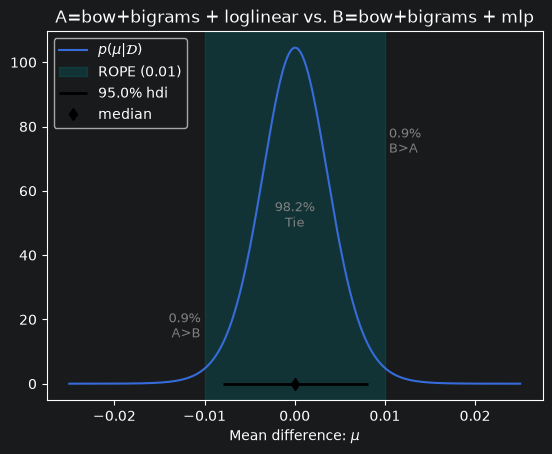

In [16]:
# The comparison that decides the winner: best system vs. runner-up
ranking = results.groupby("system")["accuracy"].mean().sort_values(ascending=False)
best, second = ranking.index[0], ranking.index[1]
print(ranking.round(4))

posterior = part1.analysis.BenavoliCorrelatedT(scores(second), scores(best), runs=len(seeds), names=[second, best])
print(f"\n{best} vs {second}: P(runner-up better), P(tie), P(best better) =", np.round(posterior.probs(rope), 3))
_ = posterior.plot(rope)

## 8. Error analysis (together)
per-class F1 and a confusion matrix

bow+bigrams + loglinear: 7411 predictions

              precision    recall  f1-score   support

         joy      0.677     0.730     0.703      1078
        fear      0.682     0.681     0.681      1068
       anger      0.498     0.507     0.503      1074
     sadness      0.614     0.599     0.606      1050
     disgust      0.569     0.593     0.581      1054
       shame      0.490     0.446     0.467      1047
       guilt      0.514     0.500     0.507      1040

    accuracy                          0.580      7411
   macro avg      0.578     0.579     0.578      7411
weighted avg      0.578     0.580     0.579      7411



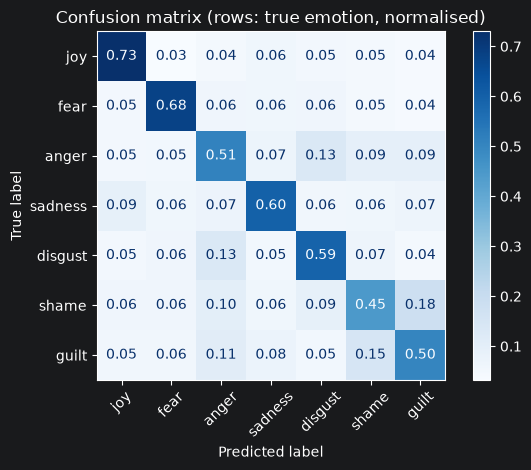

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

predictions = pd.read_csv(results_folder / "predictions.csv")

# best system, first seed: the 5 validation folds together cover every text exactly once
best_rep, best_arch = "bow+bigrams", "loglinear"
p = predictions[(predictions["representation"] == best_rep) & (predictions["architecture"] == best_arch)
                & (predictions["seed"] == seeds[0])]
print(f"{best_rep} + {best_arch}: {len(p)} predictions\n")
print(classification_report(p["y_true"], p["y_pred"], target_names=LABELS, digits=3))

ConfusionMatrixDisplay.from_predictions(p["y_true"], p["y_pred"], display_labels=LABELS, normalize="true",
                                        values_format=".2f", xticks_rotation=45, cmap="Blues")
plt.title("Confusion matrix (rows: true emotion, normalised)")
plt.tight_layout()
plt.savefig(results_folder / "confusion_matrix.png", dpi=150)
plt.show()

In [20]:
# Most frequent confusions, with a few example texts (row = index in df from section 1)
wrong = p[p["y_true"] != p["y_pred"]]
top = wrong.groupby(["y_true", "y_pred"]).size().sort_values(ascending=False).head(5)
for (t, q), n in top.items():
    print(f"\n{LABELS[t]} predicted as {LABELS[q]}: {n} times")
    for row in wrong[(wrong["y_true"] == t) & (wrong["y_pred"] == q)]["row"].head(3):
        print("   -", df["text"][row])


shame predicted as guilt: 189 times
   - When I dated a close girlfriend's boyfriend a few times. He told me that it was over between them and I accepted it. When she found out she finished our friendship.
   - When I made the same mistake that I had accused someone else of, and this was obvious to a third pereson.
   - When I stole a packet of cigarettes from a neighbour and the next day I owned up and returned it.

guilt predicted as shame: 155 times
   - When excuses are necessary and I get out of doing it myself.
   - When I was forced to decline the invitation to my mother's 70th birthday because of my work committments in another area.
   - While travelling in a bus with an invalid ticket, I got caught.

anger predicted as disgust: 143 times
   - I had a very heavy work load and two colleagues, whom I have nothing against, disturbed me by "terror ringing", i.e continously interrupting me by telephoning.
   - I saw a report on T.V news on apartheid in South Africa.
   - Jealous o